In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_csv("../data/processed/sales_analysis_ready.csv",
                 parse_dates=["order_date", "ship_date"],
                 dtype={"postal_code": str})
print(df.shape)
print(round(df["sales"].sum(), 2), round(df["profit"].sum(), 2))

(9993, 27)
2296919.49 286409.08


In [2]:
cols = ["sales", "profit", "quantity", "discount"]
summary = df[cols].describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.99]).T
summary["skew"] = df[cols].skew()
summary

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max,skew
sales,"9,993.00",229.85,623.28,0.44,7.90,17.28,54.48,209.94,572.72,"2,481.94","22,638.48",12.97
profit,"9,993.00",28.66,234.27,"-6,599.98",-15.47,1.73,8.67,29.36,89.29,580.67,"8,399.98",7.56
quantity,"9,993.00",3.79,2.23,1.00,2.00,2.00,3.00,5.00,7.00,11.00,14.00,1.28
discount,"9,993.00",0.16,0.21,0.00,0.00,0.00,0.20,0.20,0.40,0.80,0.80,1.68


In [3]:
order_df = (df.groupby("order_id")
              .agg(order_sales=("sales", "sum"),
                   order_profit=("profit", "sum"),
                   items=("row_id", "count"))
              .reset_index())

print("Orders:", len(order_df))
print(order_df[["order_sales", "order_profit", "items"]]
      .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.99]).T)
print("Mean order value:  ", round(order_df["order_sales"].mean(), 2))
print("Median order value:", round(order_df["order_sales"].median(), 2))

Orders: 5009
                count   mean    std       min    10%   25%    50%    75%  \
order_sales  5,009.00 458.56 954.73      0.56  12.84 37.63 151.96 511.95   
order_profit 5,009.00  57.18 344.94 -6,892.37 -34.77  2.05  16.28  68.69   
items        5,009.00   2.00   1.41      1.00   1.00  1.00   1.00   2.00   

                  90%      99%       max  
order_sales  1,153.83 4,209.01 23,661.23  
order_profit   198.87 1,011.49  8,762.39  
items            4.00     7.00     14.00  
Mean order value:   458.56
Median order value: 151.96


In [4]:
customer_df = (df.groupby(["customer_id", "customer_name"])
                 .agg(total_sales=("sales", "sum"),
                      total_profit=("profit", "sum"),
                      orders=("order_id", "nunique"))
                 .reset_index())

mean_spend = customer_df["total_sales"].mean()
median_spend = customer_df["total_sales"].median()

print("Customers:", len(customer_df))
print("Mean spend:  ", round(mean_spend, 2))
print("Median spend:", round(median_spend, 2))
print("Customers above the mean:", (customer_df["total_sales"] > mean_spend).sum())
print("Customers with NEGATIVE total profit:", (customer_df["total_profit"] < 0).sum())

top_n = int(len(customer_df) * 0.10)
top_share = customer_df["total_sales"].nlargest(top_n).sum() / customer_df["total_sales"].sum() * 100
print(f"Top 10% of customers ({top_n} customers) give {top_share:.2f}% of sales")
print("Skew of customer spending:", round(customer_df["total_sales"].skew(), 2))

Customers: 793
Mean spend:   2896.49
Median spend: 2256.39
Customers above the mean: 294
Customers with NEGATIVE total profit: 155
Top 10% of customers (79 customers) give 30.62% of sales
Skew of customer spending: 2.48


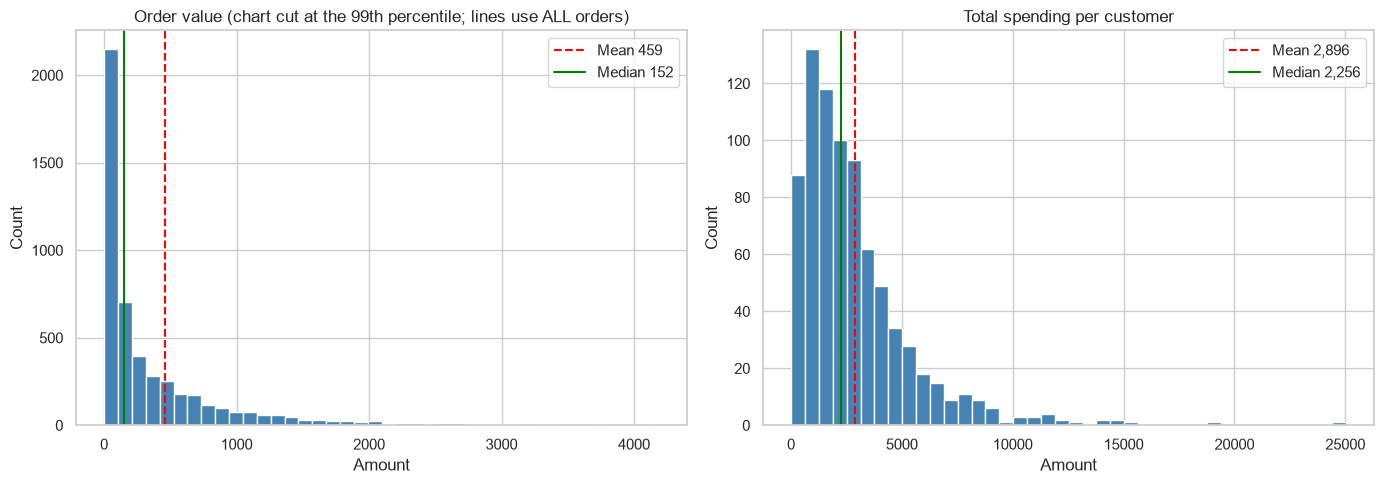

In [5]:
def hist_with_lines(ax, data, title, cut=None):
    shown = data if cut is None else data[data <= data.quantile(cut)]
    ax.hist(shown, bins=40, color="steelblue", edgecolor="white")
    ax.axvline(data.mean(), color="red", linestyle="--", label=f"Mean {data.mean():,.0f}")
    ax.axvline(data.median(), color="green", linestyle="-", label=f"Median {data.median():,.0f}")
    ax.set_title(title)
    ax.set_xlabel("Amount")
    ax.set_ylabel("Count")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
hist_with_lines(axes[0], order_df["order_sales"],
                "Order value (chart cut at the 99th percentile; lines use ALL orders)", cut=0.99)
hist_with_lines(axes[1], customer_df["total_sales"], "Total spending per customer")
plt.tight_layout()
plt.savefig("../images/stats_01_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

PEARSON
           sales  quantity  discount  profit
sales      1.00      0.20     -0.03    0.48
quantity   0.20      1.00      0.01    0.07
discount  -0.03      0.01      1.00   -0.22
profit     0.48      0.07     -0.22    1.00 

SPEARMAN
           sales  quantity  discount  profit
sales      1.00      0.33     -0.06    0.52
quantity   0.33      1.00     -0.00    0.23
discount  -0.06     -0.00      1.00   -0.54
profit     0.52      0.23     -0.54    1.00


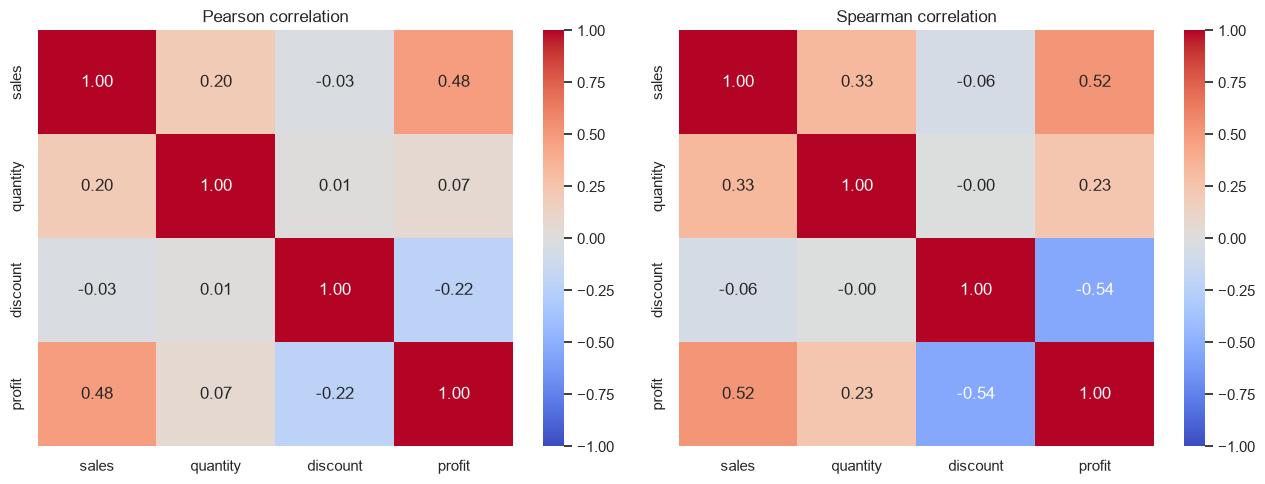

In [6]:
corr_cols = ["sales", "quantity", "discount", "profit"]
pearson = df[corr_cols].corr(method="pearson")
spearman = df[corr_cols].corr(method="spearman")
print("PEARSON\n", pearson, "\n")
print("SPEARMAN\n", spearman)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, table, name in [(axes[0], pearson, "Pearson"), (axes[1], spearman, "Spearman")]:
    sns.heatmap(table, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(name + " correlation")
plt.tight_layout()
plt.savefig("../images/stats_02_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
df["discount_band"] = pd.cut(df["discount"],
                             bins=[-0.001, 0, 0.20, 1.0],
                             labels=["No discount", "Up to 20%", "30% or more"])

band_table = (df.groupby("discount_band", observed=True)
                .agg(lines=("row_id", "count"),
                     sales=("sales", "sum"),
                     profit=("profit", "sum"),
                     median_profit=("profit", "median"),
                     pct_lines_losing=("profit", lambda s: (s < 0).mean() * 100)))
band_table["margin_%"] = band_table["profit"] / band_table["sales"] * 100
band_table

,lines,sales,profit,median_profit,pct_lines_losing,margin_%
discount_band,,,,,,
No discount,4798,"1,087,908.47","320,987.60",16.00,0.00,29.51
Up to 20%,3803,"846,522.24","100,785.47",6.75,13.75,11.91
30% or more,1392,"362,488.78","-135,364.00",-18.35,96.77,-37.34


In [8]:
no_disc  = df.loc[df["discount_band"] == "No discount", "profit"]
big_disc = df.loc[df["discount_band"] == "30% or more", "profit"]

u_stat, p_value = stats.mannwhitneyu(no_disc, big_disc, alternative="two-sided")
prob_higher = u_stat / (len(no_disc) * len(big_disc))

rho, p_rho = stats.spearmanr(df["discount"], df["profit"])

print("Median profit, no discount :", round(no_disc.median(), 2))
print("Median profit, 30% or more :", round(big_disc.median(), 2))
print(f"Mann-Whitney p-value: {p_value:.3e}")
print(f"Chance a random no-discount line beats a random 30%+ line: {prob_higher:.3f}")
print(f"Spearman rho (discount vs profit): {rho:.3f}   p-value: {p_rho:.3e}")

Median profit, no discount : 16.0
Median profit, 30% or more : -18.35
Mann-Whitney p-value: 0.000e+00
Chance a random no-discount line beats a random 30%+ line: 0.985
Spearman rho (discount vs profit): -0.543   p-value: 0.000e+00


In [9]:
def margin_tables(group_col):
    t = (df.groupby([group_col, "discount_band"], observed=True)
           .agg(sales=("sales", "sum"), profit=("profit", "sum"), lines=("row_id", "count")))
    t["margin_%"] = t["profit"] / t["sales"] * 100
    return t["margin_%"].unstack("discount_band"), t["lines"].unstack("discount_band")

for col in ["category", "region"]:
    margins, counts = margin_tables(col)
    print(f"\nMARGIN % by {col} and discount group")
    print(margins)
    print(f"\nNUMBER OF LINES by {col} and discount group")
    print(counts)


MARGIN % by category and discount group
discount_band    No discount  Up to 20%  30% or more
category                                            
Furniture              22.71       5.09       -27.95
Office Supplies        29.52      16.48      -119.27
Technology             33.96      14.72       -26.35

NUMBER OF LINES by category and discount group
discount_band    No discount  Up to 20%  30% or more
category                                            
Furniture                836        743          541
Office Supplies         3129       2217          680
Technology               833        843          171

MARGIN % by region and discount group
discount_band  No discount  Up to 20%  30% or more
region                                            
Central              31.31      12.39       -40.57
East                 30.84      14.77       -28.90
South                29.16       8.24       -35.18
West                 26.65      11.37       -93.94

NUMBER OF LINES by region and disco

In [10]:
sub = (df.groupby("sub_category")
         .agg(lines=("row_id", "count"),
              avg_discount=("discount", "mean"),
              pct_lines_30plus=("discount", lambda s: (s >= 0.30).mean() * 100),
              profit=("profit", "sum"))
         .sort_values("profit"))
sub

,lines,avg_discount,pct_lines_30plus,profit
sub_category,,,,
Tables,319,0.26,55.17,"-17,725.48"
Bookcases,228,0.21,30.70,"-3,472.56"
Supplies,190,0.08,0.00,"-1,189.10"
Fasteners,217,0.08,0.00,949.52
Machines,115,0.31,46.09,"3,384.76"
Labels,364,0.07,0.00,"5,546.25"
Art,796,0.07,0.00,"6,527.79"
Envelopes,254,0.08,0.00,"6,964.18"
Furnishings,957,0.14,14.42,"13,059.14"


## Statistical findings

**1. Orders and customers are very uneven.**
Finding: The mean order value is 458.56, but the median is only 151.96, so the average is about 3 times the middle order. For customers, the mean spend is 2,896.49 and the median is 2,256.39 (skew 2.48). The top 10% of customers (79 customers) give 30.62% of sales.
Insight: A small number of big orders and big customers pull the average up. For a "typical" order or customer, the median is a fairer number than the mean.

**2. Higher discounts go with lower profit.**
Finding: Lines with no discount have a median profit of 16.00, and none of them lose money (margin 29.51%). Lines with up to 20% discount have a median profit of 6.75, and 13.75% lose money (margin 11.91%). Lines with 30% or more have a median profit of -18.35, and 96.77% lose money (margin -37.34%). The Spearman correlation between discount and profit is -0.543. In the Mann-Whitney test the p-value is extremely small, and a random no-discount line has higher profit than a random 30%+ line 98.5% of the time.
Insight: The gap is large and is not just luck. Discounts of 30% or more are the first thing to review.

**3. The pattern holds inside every category and region.**
Finding: The margin falls from "no discount" to "30% or more" in all 3 categories and all 4 regions. So the link is not caused only by one category or one region.
Careful: Some groups have few lines (for example West with 30%+ has only 118 lines), so those margins can swing a lot.

**4. Discount is not the only reason for losses.**
Finding: Tables have an average discount of 0.26, and 55.17% of their lines are at 30% or more; their total profit is -17,725.48. Bookcases have 30.70% such lines and a profit of -3,472.56. But Supplies lose money (-1,189.10) with 0% of lines at 30% or more, while Binders (40.25% of lines at 30%+) and Chairs (25.49%) still make a profit.
Insight: Heavy discounts fit the Tables story, but cost and product mix probably matter too.

**5. Central's low margin goes with its many heavy discounts.**
Finding: Central has 643 of the 1,392 lines with 30%+ discount (about 46%). Its margin on no-discount lines (31.31%) is not lower than the other regions (26.65% to 30.84%).
Insight: Central's low overall margin (7.92%) looks linked to how many heavy-discount lines it has, not to weak normal sales. This is a link, not proof.

**6. Many customers cost the business money.**
Finding: 155 of 793 customers (about 19.5%) have a negative total profit.
Insight: Ranking customers only by sales hides this. Profit should be checked too.

**What we cannot say**
- The data shows links, not causes. We do not know why each discount was given.
- There is no cost price in the dataset, so we cannot see whether the discounted price was below cost.
- Lines from the same order may be related, so the p-value is a bit too optimistic. The size of the gap is the stronger evidence.
- This is sample data from a made-up store.